# Boundary finding with tunable bag calibration

The zero-temperature calibration is controlled by

$$
n_B^{\rm crit}(T=0)=x\,n_0.
$$

For each hidden ray angle $\theta$, the upstream point is

$$
\frac{n_B(0^-)}{n_0}=n_{\rm origin}+\rho\,n_{\rm scale}\cos\theta,
\qquad
T(0^-)=\rho\,T_{\rm scale}\sin\theta.
$$

The complete $0^-$ state is known at every trial $\rho$. At prescribed $T(0^+)$, the only $0^+$ unknowns are $\mu_B(0^+)$ and $\mu_K(0^+)$, fixed by

$$
P_{\rm QM}\!\left(\mu_B(0^+),\mu_K(0^+),T(0^+)\right)
=P_{\rm PNM}\!\left(n_B(0^-),T(0^-)\right),
$$

$$
\frac{h_{\rm QM}\!\left(\mu_B(0^+),\mu_K(0^+),T(0^+)\right)}
{n_{B,{\rm QM}}\!\left(\mu_B(0^+),\mu_K(0^+),T(0^+)\right)}
=\frac{h_{\rm PNM}\!\left(n_B(0^-),T(0^-)\right)}{n_B(0^-)}.
$$

The inner boundary additionally imposes $\mu_K(0^+)=0$. The cold outer boundary imposes $n_s(0^+)=0$, implemented with the equivalent, better-conditioned condition $\mu_s(0^+)=0$ and verified using $a(0^+)=n_K(0^+)/n_B(0^+)=1$. No velocity calculation or BVP enters either solve.


In [ ]:
from functools import lru_cache
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq, least_squares
from tqdm import tqdm
from RMFsolver import constants as const
from RMFsolver import phase_velocity as pv

# Tunable physical and calculation parameters
NB_CRIT_0_OVER_N0 = 4.0
STABLE_T_0PLUS_MEV = 0.1
A_COLD_T_MEV = 1.0e-3
DENSITY_ORIGIN_OVER_N0 = 1.0
DENSITY_MAX_OVER_N0 = 7.0
TEMPERATURE_MAX_MEV = 170.0
THETA_COUNT = 18
MS_MEV = 0.0
UPB = 5000
ROOT_TOLERANCE = 2.0e-7
N0 = const.NuclearDensity_nucleons_MeV3
THETA_AXIS = np.linspace(0.0, 0.5*np.pi, THETA_COUNT)
DENSITY_SCALE_OVER_N0 = DENSITY_MAX_OVER_N0-DENSITY_ORIGIN_OVER_N0
TEMPERATURE_SCALE_MEV = TEMPERATURE_MAX_MEV

def bracketed_root(function, grid, prefer):
    grid = np.asarray(grid, dtype=float)
    values = np.array([function(x) for x in grid], dtype=float)
    changes = np.where(np.isfinite(values[:-1]) & np.isfinite(values[1:])
                       & (values[:-1]*values[1:] <= 0.0))[0]
    if not changes.size:
        raise RuntimeError("calibration root is not bracketed")
    midpoints = 0.5*(grid[changes]+grid[changes+1])
    index = int(changes[np.argmin(abs(midpoints-prefer))])
    return float(brentq(function, grid[index], grid[index+1], xtol=1e-8, rtol=1e-11))

def calibrate_b14(nB_crit_0_over_n0=NB_CRIT_0_OVER_N0):
    nB_crit = float(nB_crit_0_over_n0)*N0
    P_crit = float(pv.PNM_n(nB_crit, 0.0, NM_type="PNM"))
    muB_crit = bracketed_root(lambda muB: pv.PNM(muB, 0.0, NM_type="PNM")-P_crit,
                              np.linspace(850.0, 1600.0, 180), 1050.0)
    B14 = bracketed_root(lambda bag: pv.PQM(muB_crit, 0.0, bag, 0.0, ms=MS_MEV)-P_crit,
                         np.linspace(110.0, 270.0, 241), 180.0)
    return {"nB_crit_0_over_n0": float(nB_crit_0_over_n0), "B14_MeV": B14,
            "muB_crit_0_MeV": muB_crit, "P_crit_0_MeV4": P_crit}

# Calibration is initialized only when the load-or-calculate cell needs a new solve.

@lru_cache(maxsize=2048)
def upstream(T_0minus, nB_0minus_over_n0):
    nB_0minus = float(nB_0minus_over_n0)*N0
    T_0minus = float(T_0minus)
    P_0minus = float(pv.PNM_n(nB_0minus, T_0minus, NM_type="PNM"))
    h_0minus = float(pv.hNM_n(nB_0minus, T_0minus))
    if not np.all(np.isfinite([P_0minus, h_0minus])) or h_0minus <= 0.0:
        raise RuntimeError("upstream fixed-density thermodynamics are not physical")
    return {"P_0minus": P_0minus, "h_over_nB_0minus": h_0minus/nB_0minus}

def matching_residuals(muB_0plus, muK_0plus, T_0minus, nB_0minus_over_n0, T_0plus):
    state = upstream(float(T_0minus), float(nB_0minus_over_n0))
    P_0plus = pv.PQM(muB_0plus, muK_0plus, B14, T_0plus, ms=MS_MEV, upB=UPB)
    h_0plus = pv.hQM(muB_0plus, muK_0plus, B14, T_0plus, ms=MS_MEV, upB=UPB)
    nB_0plus = pv.nB_QM(muB_0plus, muK_0plus, B14, T_0plus, ms=MS_MEV, upB=UPB)
    return np.array([(P_0plus-state["P_0minus"])/max(abs(state["P_0minus"]), 1.0),
                     (h_0plus/nB_0plus-state["h_over_nB_0minus"])
                     /state["h_over_nB_0minus"]])

def quark_outputs(muB_0plus, muK_0plus, T_0plus):
    state = pv._quark_uds_state(muB_0plus, muK_0plus, T_0plus, ms=MS_MEV, upB=UPB)
    nB_0plus, nK_0plus = state["nB"], state["nK"]
    return {"mu_s": float(state["chemical_potentials"]["mu_s"]),
            "n_s_0plus": float(state["species"]["n_s"]),
            "nB_0plus": float(nB_0plus), "nK_0plus": float(nK_0plus),
            "a_0plus": float(nK_0plus/nB_0plus)}

def rho_limit(theta):
    cosine, sine = np.cos(theta), np.sin(theta)
    limits = []
    if cosine > 1e-12:
        limits.append((DENSITY_MAX_OVER_N0-DENSITY_ORIGIN_OVER_N0)
                      /(DENSITY_SCALE_OVER_N0*cosine))
    if sine > 1e-12:
        limits.append(TEMPERATURE_MAX_MEV/(TEMPERATURE_SCALE_MEV*sine))
    return float(min(limits))

def physical_point(theta, rho):
    return (float(DENSITY_ORIGIN_OVER_N0+rho*DENSITY_SCALE_OVER_N0*np.cos(theta)),
            float(rho*TEMPERATURE_SCALE_MEV*np.sin(theta)))

def solve_ray_root(theta, condition, guess):
    limit = rho_limit(theta)
    muB_0minus = float("nan")
    if condition == "muK":
        def residual(z):
            n_over, T = physical_point(theta, z[0])
            return matching_residuals(1000*z[1], 0.0, T, n_over, STABLE_T_0PLUS_MEV)
        seeds = (guess, (min(0.5, 0.8*limit), CALIBRATION["muB_crit_0_MeV"]/1000))
        bounds = ([0.0, 0.3], [limit, 3.0])
    elif condition == "ns":
        def residual(z):
            n_over, T = physical_point(theta, z[0])
            muB_0minus_trial = 1000*z[1]
            muB_0plus, muK_0plus = 1000*z[2], 100*z[3]
            P_0minus, e_0minus, nB_0minus, _ = pv._validated_pnm_state(
                muB_0minus_trial, T, pv.para.paraQMCRMF3
            )
            state_0plus = pv._quark_uds_state(
                muB_0plus, muK_0plus, A_COLD_T_MEV, ms=MS_MEV, upB=UPB
            )
            P_0plus = pv.PQM(
                muB_0plus, muK_0plus, B14, A_COLD_T_MEV, ms=MS_MEV, upB=UPB
            )
            h_0plus = pv.hQM(
                muB_0plus, muK_0plus, B14, A_COLD_T_MEV, ms=MS_MEV, upB=UPB
            )
            h_over_nB_0minus = (P_0minus+e_0minus)/nB_0minus
            return np.array([
                nB_0minus/(n_over*N0)-1.0,
                (P_0plus-P_0minus)/max(abs(P_0minus), 1.0),
                (h_0plus/state_0plus["nB"]-h_over_nB_0minus)/h_over_nB_0minus,
                state_0plus["chemical_potentials"]["mu_s"]/1000,
            ])
        fallback_muB_0minus = max(1.4, 1.3*CALIBRATION["muB_crit_0_MeV"]/1000)
        seeds = (guess, (min(0.8, 0.8*limit), fallback_muB_0minus, 1.1, 6.2))
        bounds = ([0.0, 0.3, 0.3, 0.0], [limit, 3.0, 3.0, 20.0])
    else:
        raise ValueError("condition must be 'muK' or 'ns'")
    candidates = []
    for seed in seeds:
        clipped = np.clip(np.asarray(seed, dtype=float), np.asarray(bounds[0])+1e-8,
                          np.asarray(bounds[1])-1e-8)
        try:
            solution = least_squares(residual, clipped, bounds=bounds, diff_step=1e-4,
                                     xtol=1e-11, ftol=1e-11, gtol=1e-11, max_nfev=220)
            norm = float(np.linalg.norm(residual(solution.x), ord=np.inf))
        except Exception:
            continue
        if np.all(np.isfinite(solution.x)):
            candidates.append((norm, solution.x))
        if norm <= ROOT_TOLERANCE:
            break
    if not candidates:
        raise RuntimeError(f"{condition} ray root failed at theta={theta:.6g}; no finite candidate")
    norm, solved = min(candidates, key=lambda item: item[0])
    if norm > ROOT_TOLERANCE:
        raise RuntimeError(f"{condition} ray root failed at theta={theta:.6g}; residual={norm:.3e}")
    rho = float(solved[0])
    if condition == "muK":
        muB_0plus, muK_0plus = float(1000*solved[1]), 0.0
    else:
        muB_0minus = float(1000*solved[1])
        muB_0plus, muK_0plus = float(1000*solved[2]), float(100*solved[3])
    n_over, T = physical_point(theta, rho)
    outputs = quark_outputs(muB_0plus, muK_0plus,
                            STABLE_T_0PLUS_MEV if condition == "muK" else A_COLD_T_MEV)
    return {"condition": condition, "theta_rad": float(theta), "theta_deg": float(np.degrees(theta)),
            "rho": rho, "nB_0minus_over_n0": n_over, "T_0minus_MeV": T,
            "muB_0minus_MeV": muB_0minus, "muB_0plus_MeV": muB_0plus,
            "muK_0plus_MeV": muK_0plus,
            "n_s_over_nB": outputs["n_s_0plus"]/outputs["nB_0plus"],
            "a_0plus": outputs["a_0plus"], "residual_norm": norm,
            "solver_vector": solved}

def solve_boundary(condition, initial_guess):
    rows, guess = [], initial_guess
    for theta in tqdm(THETA_AXIS, desc=condition, unit="ray"):
        row = solve_ray_root(float(theta), condition=condition, guess=guess)
        rows.append(row)
        guess = tuple(row["solver_vector"])
    return rows


## Load saved boundaries, calculate only missing cases

All three stable-neutron boundaries use $T(0^+)=0.1$ MeV. The saved $3n_0$ cold boundary uses $T(0^+)=0$; the $2n_0$ and $4n_0$ cold solves use $10^{-3}$ MeV. The source temperatures are retained in the report below.
Existing cluster results are read directly; a new calculation is needed only when neither a saved domain nor a local cache exists.
Set `FORCE_RECOMPUTE` only to deliberately rerun the boundary solves.
Each new calculation retains the existing adjacent-angle continuation and validated cold-interface solver.

In [ ]:
# Tunable comparison and cache parameters
CALIBRATIONS_OVER_N0 = (2.0, 3.0, 4.0)
CACHE_DIRECTORY = "local_analysis_results/FL26-3"
FORCE_RECOMPUTE = False
SAVED_DOMAIN_PATHS = {
    2.0: "new_paper_calculations/26-09-03/Full_scan/T0plus0p1-ncrit2-domain.npy",
    3.0: "new_paper_calculations/26-08-21/T0plus0p1-domain.npy",
}
from pathlib import Path

def read_cluster_boundaries(path, ncrit):
    domain = np.load(path, allow_pickle=True).item()
    boundary = domain["boundary_diagnostics"]["semi_analytic"]
    if not np.isclose(domain["calibration"]["ncrit_over_n0"], ncrit):
        raise ValueError(f"Wrong calibration in {path}")
    cold_T = float(boundary["A_boundary_T_0plus_MeV"])
    if not (np.isclose(cold_T, 0.0) or np.isclose(cold_T, A_COLD_T_MEV)):
        raise ValueError(f"Wrong cold-interface temperature in {path}")
    key = next(key for key in boundary["gap_curve_records_by_T0plus"]
               if np.isclose(float(key), STABLE_T_0PLUS_MEV))
    def physical_records(records):
        return [{**row, "nB_0minus_over_n0": row["nB_over_n0"],
                 "T_0minus_MeV": row["T_MeV"]} for row in records]
    return {"ncrit_over_n0": ncrit, "B14_MeV": domain["calibration"]["B14_MeV"],
            "stable_T_0plus_MeV": STABLE_T_0PLUS_MEV, "A_cold_T_MeV": cold_T,
            "source": str(path),
            "stable_records": physical_records(boundary["gap_curve_records_by_T0plus"][key]),
            "A_records": physical_records(boundary["A_curve_records"])}

cache_directory = Path(CACHE_DIRECTORY)
cache_directory.mkdir(parents=True, exist_ok=True)
boundary_sets, report = {}, []
for ncrit in CALIBRATIONS_OVER_N0:
    started = perf_counter()
    cache = cache_directory / f"boundaries-ncrit{ncrit:g}-T0plus{STABLE_T_0PLUS_MEV:g}-cold{A_COLD_T_MEV:g}.npy"
    saved_domain = Path(SAVED_DOMAIN_PATHS[ncrit]) if ncrit in SAVED_DOMAIN_PATHS else None
    if not FORCE_RECOMPUTE and saved_domain is not None and saved_domain.exists():
        payload = read_cluster_boundaries(saved_domain, ncrit)
        action = "loaded cluster data"
    elif not FORCE_RECOMPUTE and cache.exists():
        payload = np.load(cache, allow_pickle=True).item()
        action = "loaded local cache"
    else:
        CALIBRATION = calibrate_b14(ncrit)
        B14 = CALIBRATION["B14_MeV"]
        upstream.cache_clear()
        stable_guess = ((ncrit-DENSITY_ORIGIN_OVER_N0)/DENSITY_SCALE_OVER_N0,
                        CALIBRATION["muB_crit_0_MeV"]/1000)
        A_guess = (0.8, max(1.4, 1.3*CALIBRATION["muB_crit_0_MeV"]/1000), 1.1, 6.2)
        stable_rows = solve_boundary(condition="muK", initial_guess=stable_guess)
        A_rows = solve_boundary(condition="ns", initial_guess=A_guess)
        payload = {"ncrit_over_n0": ncrit, "B14_MeV": B14,
                   "stable_T_0plus_MeV": STABLE_T_0PLUS_MEV, "A_cold_T_MeV": A_COLD_T_MEV,
                   "source": str(cache), "stable_records": stable_rows, "A_records": A_rows}
        np.save(cache, payload, allow_pickle=True)
        action = "calculated and cached"
    for key, expected in (("ncrit_over_n0", ncrit), ("stable_T_0plus_MeV", STABLE_T_0PLUS_MEV)):
        if not np.isclose(payload[key], expected):
            raise ValueError(f"Incompatible {key} in {payload['source']}")
    boundary_sets[ncrit] = payload
    report.append({"ncrit/n0": ncrit, "B14 [MeV]": payload["B14_MeV"], "action": action,
                   "stable points": len(payload["stable_records"]), "A points": len(payload["A_records"]), "cold T [MeV]": payload["A_cold_T_MeV"],
                   "seconds": perf_counter()-started})
display(pd.DataFrame(report))


Recovered previously saved figure: local_analysis_results/FL26-3/numerical-boundary-comparison-ncrit2-3-4.png
No new calculation was performed during recovery.


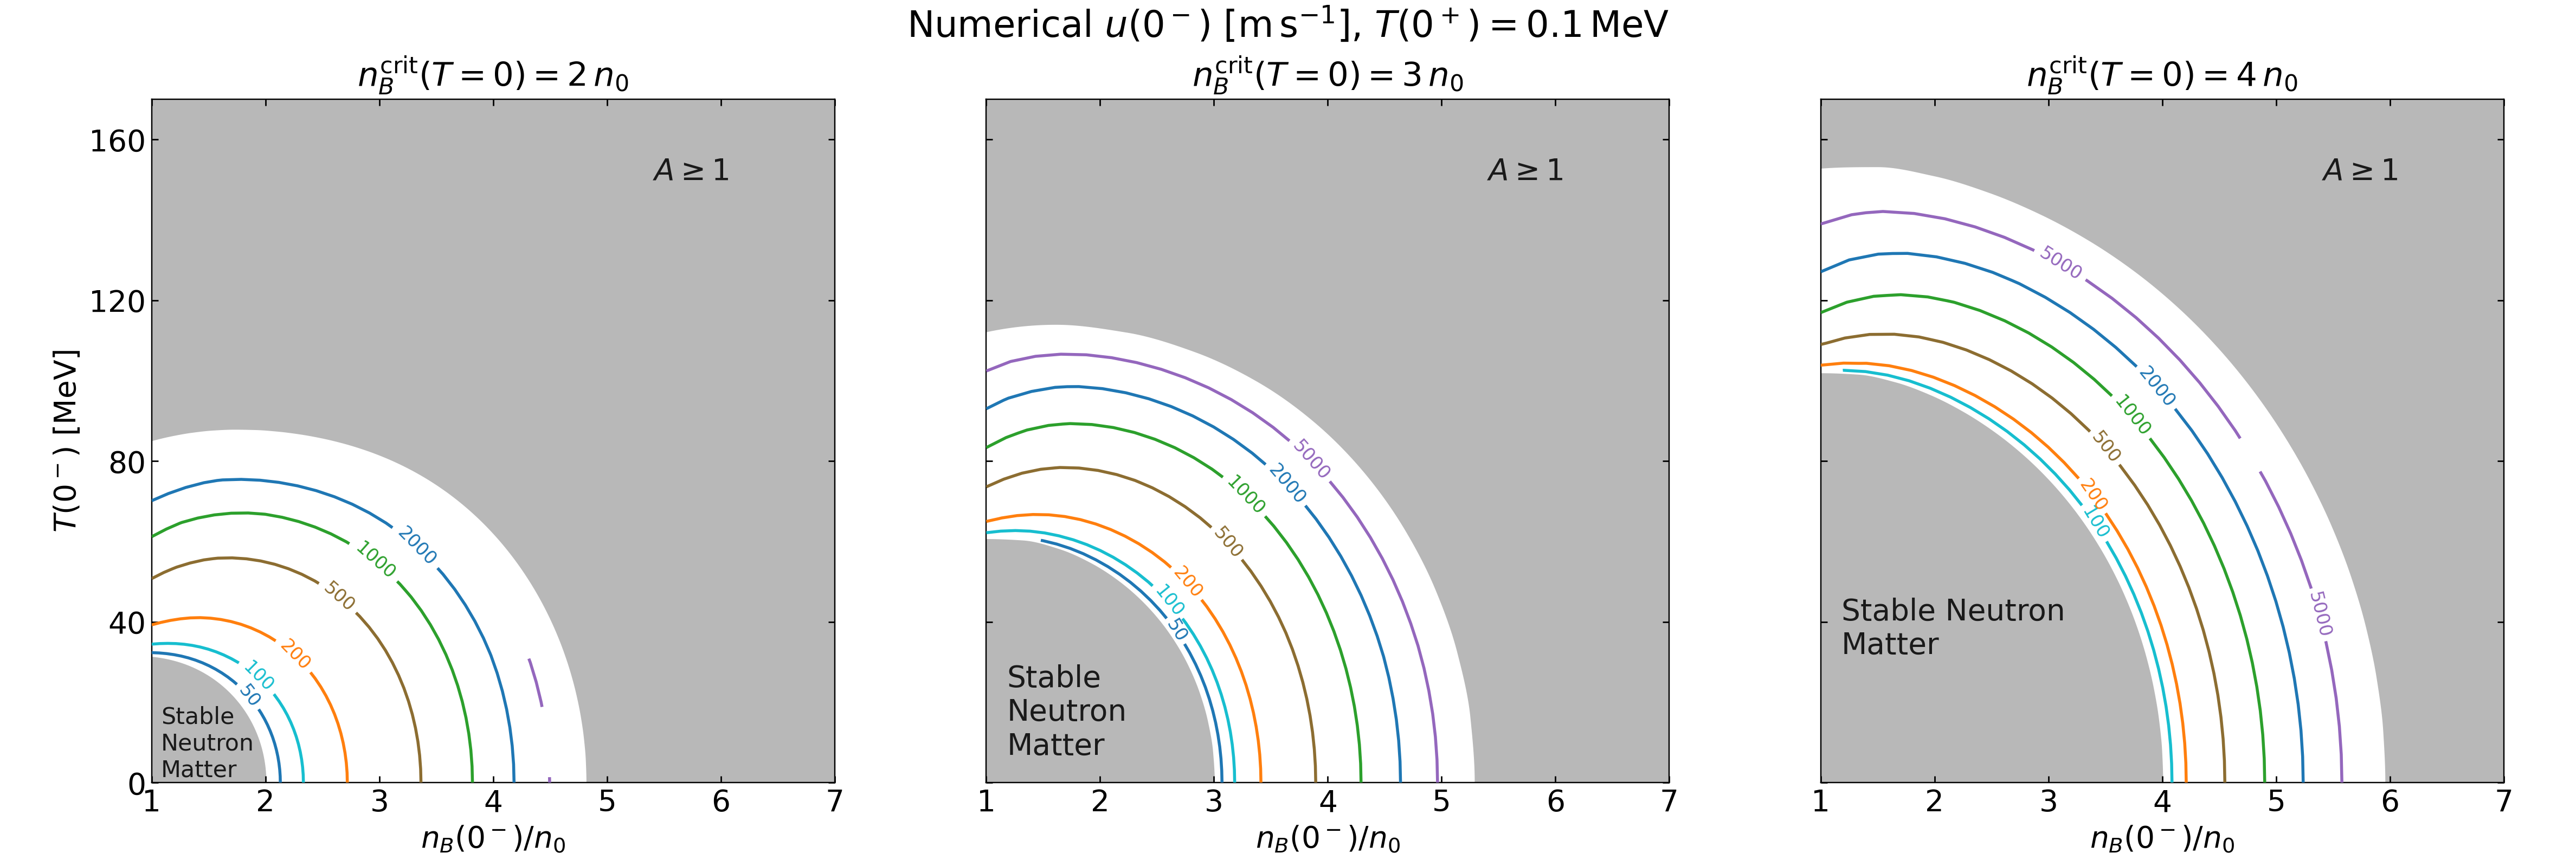

In [ ]:
# Tunable plotting parameters
CONTOUR_PATHS = {
    2.0: "new_paper_calculations/26-09-03/Full_scan/T0plus0p1-ncrit2-uNmax-angular-wavefront.npy",
    3.0: "new_paper_calculations/26-08-24/T0plus0p1-uNmax-state-of-art-complete-5km.npy",
    4.0: "new_paper_calculations/26-09-08/Full_scan/T0plus0p1-ncrit4-uNmax-angular-wavefront.npy",
}
CONTOUR_T_0PLUS_MEV = 0.1
VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0)
VELOCITY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4", "#9467bd")
CONTOUR_LINE_WIDTH = 1.8
CONTOUR_LINE_STYLE = "-"
CONTOUR_ZORDER = 3
CONTOUR_CORNER_MASK = True
CONTOUR_LABEL_FONT_SIZE = 11
CONTOUR_LABEL_FORMAT = "%g"
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
FIGURE_TITLE = r"Numerical $u(0^-)$ [$\mathrm{m\,s^{-1}}$], $T(0^+)=0.1\,\mathrm{MeV}$"
FIGURE_TITLE_FONT_SIZE = 22
FIGURE_SIZE = (21.6, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
CONSTRAINED_LAYOUT = True
BOX_ASPECT = 1.0
X_LIMITS = (1.0, 7.0)
Y_LIMITS_MEV = (0.0, 170.0)
X_TICKS = (1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0)
Y_TICKS_MEV = (0.0, 40.0, 80.0, 120.0, 160.0)
X_SCALE = "linear"
Y_SCALE = "linear"
BACKGROUND_COLOR = "white"
EXCLUDED_REGION_COLOR = "0.72"
EXCLUDED_REGION_ALPHA = 1.0
REGION_ZORDER = 0
BOUNDARY_SAMPLES = 401
TITLE_TEMPLATE = r"$n_B^{\rm crit}(T=0)=%g\,n_0$"
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = r"$n_B(0^-)/n_0$"
Y_LABEL = r"$T(0^-)$ [MeV]"
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
REGION_TEXT_COLOR = "0.10"
REGION_TEXT_FONT_SIZE = 18
INNER_TEXT_FONT_SIZES = {2.0: 14, 3.0: 18, 4.0: 18}
REGION_TEXT_ZORDER = 5
A_REGION_TEXT = r"$A\geq 1$"
A_REGION_TEXT_POSITION = (5.4, 150.0)
INNER_REGION_TEXTS = {2.0: "Stable\nNeutron\nMatter",
                      3.0: "Stable\nNeutron\nMatter", 4.0: "Stable Neutron\nMatter"}
INNER_TEXT_POSITIONS = {2.0: (1.08, 1.5), 3.0: (1.18, 7.0), 4.0: (1.18, 32.0)}
OUTPUT_PNG = "local_analysis_results/FL26-3/numerical-boundary-comparison-ncrit2-3-4.png"
OUTPUT_PDF = "local_analysis_results/FL26-3/numerical-boundary-comparison-ncrit2-3-4.pdf"

from scipy.interpolate import PchipInterpolator

def read_numerical_contour(path, ncrit):
    payload = np.load(path, allow_pickle=True).item()
    calibration = payload["calibration"]
    if not np.isclose(calibration["ncrit_over_n0"], ncrit):
        raise ValueError(f"Wrong contour calibration in {path}")
    if not np.isclose(calibration["B14_MeV"], boundary_sets[ncrit]["B14_MeV"]):
        raise ValueError(f"Contour and boundary bag constants differ in {path}")
    temperatures = np.atleast_1d(payload.get("T_0plus_values_MeV", payload.get("T_0plus_MeV")))
    if temperatures.size != 1 or not np.isclose(temperatures[0], CONTOUR_T_0PLUS_MEV):
        raise ValueError(f"Wrong contour interface temperature in {path}")
    if not np.isclose(boundary_sets[ncrit]["stable_T_0plus_MeV"], CONTOUR_T_0PLUS_MEV):
        raise ValueError("Contour and stable-boundary temperatures differ")
    if "plot_success_grid" in payload:
        # The merged 3n0 artifact supplies its verified, complete-5km/s plotting grid.
        density = np.asarray(payload["plot_nB_0minus_over_n0_grid"])
        temperature = np.asarray(payload["plot_T_0minus_MeV_grid"])
        velocity = np.asarray(payload["plot_u_0minus_m_s_grid"])
        success = np.asarray(payload["plot_success_grid"], dtype=bool)
    else:
        density = np.asarray(payload["nB_0minus_over_n0_grid"])[:, :, 0]
        temperature = np.asarray(payload["T_0minus_MeV_grid"])[:, :, 0]
        velocity = np.asarray(payload["numerical_outward_u_0minus_m_s_grid"])[:, :, 0]
        success = np.asarray(payload["numerical_outward_success_grid"], dtype=bool)[:, :, 0]
    if not (density.shape == temperature.shape == velocity.shape == success.shape):
        raise ValueError(f"Inconsistent contour grid shapes in {path}")
    if not np.all(np.isfinite(density) & np.isfinite(temperature)):
        raise ValueError(f"Nonfinite contour coordinates in {path}")
    accepted = success & np.isfinite(velocity) & (velocity > 0.0)
    report = {"ncrit/n0": ncrit, "accepted plotting cells": int(accepted.sum()),
              "plotting cells": accepted.size,
              "terminal cells": payload.get("completed_cell_count", accepted.size),
              "run complete": payload.get("run_complete", "merged successes"), "source": path}
    return density, temperature, np.ma.masked_where(~accepted, velocity), report

def physical_curve(records):
    rows = sorted(records, key=lambda row: row["theta_rad"])
    theta = np.array([row["theta_rad"] for row in rows])
    points = np.array([[row["nB_0minus_over_n0"], row["T_0minus_MeV"]] for row in rows])
    if not np.all(np.isfinite(points)) or not np.all(np.diff(theta) > 0):
        raise ValueError("Boundary points must be finite and ordered on distinct rays")
    return PchipInterpolator(theta, points, axis=0)(np.linspace(theta[0], theta[-1], BOUNDARY_SAMPLES)).T

fig, axes = plt.subplots(1, len(CALIBRATIONS_OVER_N0), figsize=FIGURE_SIZE, dpi=FIGURE_DPI,
                         sharex=True, sharey=True, constrained_layout=CONSTRAINED_LAYOUT,
                         facecolor=BACKGROUND_COLOR)
fig.suptitle(FIGURE_TITLE, fontsize=FIGURE_TITLE_FONT_SIZE)
contour_report = []
for ax, ncrit in zip(axes, CALIBRATIONS_OVER_N0):
    inner_x, inner_y = physical_curve(boundary_sets[ncrit]["stable_records"])
    outer_x, outer_y = physical_curve(boundary_sets[ncrit]["A_records"])
    ax.set_facecolor(BACKGROUND_COLOR)
    ax.fill(np.r_[inner_x, X_LIMITS[0], inner_x[0]],
            np.r_[inner_y, Y_LIMITS_MEV[0], Y_LIMITS_MEV[0]],
            color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=REGION_ZORDER)
    ax.fill(np.r_[outer_x, X_LIMITS[0], X_LIMITS[1], X_LIMITS[1], outer_x[0]],
            np.r_[outer_y, Y_LIMITS_MEV[1], Y_LIMITS_MEV[1], Y_LIMITS_MEV[0], Y_LIMITS_MEV[0]],
            color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=REGION_ZORDER)
    density, temperature, velocity, status = read_numerical_contour(CONTOUR_PATHS[ncrit], ncrit)
    contour_report.append(status)
    # Only draw levels bracketed by actual accepted values; no extrapolated velocities.
    selected = [(level, color) for level, color in zip(VELOCITY_CONTOUR_LEVELS_M_S, VELOCITY_CONTOUR_COLORS)
                if velocity.count() and velocity.min() < level < velocity.max()]
    if selected:
        levels, colors = zip(*selected)
        contours = ax.contour(density, temperature, velocity, levels=levels, colors=colors,
                              linewidths=CONTOUR_LINE_WIDTH, linestyles=CONTOUR_LINE_STYLE,
                              corner_mask=CONTOUR_CORNER_MASK, zorder=CONTOUR_ZORDER)
        ax.clabel(contours, inline=CONTOUR_LABEL_INLINE, fmt=CONTOUR_LABEL_FORMAT,
                  fontsize=CONTOUR_LABEL_FONT_SIZE, inline_spacing=CONTOUR_LABEL_INLINE_SPACING)
    ax.text(*A_REGION_TEXT_POSITION, A_REGION_TEXT, color=REGION_TEXT_COLOR,
            fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
    ax.text(*INNER_TEXT_POSITIONS[ncrit], INNER_REGION_TEXTS[ncrit], color=REGION_TEXT_COLOR,
            fontsize=INNER_TEXT_FONT_SIZES[ncrit], zorder=REGION_TEXT_ZORDER)
    ax.set(xlim=X_LIMITS, ylim=Y_LIMITS_MEV, xscale=X_SCALE, yscale=Y_SCALE)
    ax.set_xticks(X_TICKS)
    ax.set_yticks(Y_TICKS_MEV)
    ax.set_box_aspect(BOX_ASPECT)
    ax.set_title(TITLE_TEMPLATE % ncrit, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
    ax.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    ax.tick_params(direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT,
                   length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE)
    for spine in ax.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)
axes[0].set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
for output in (OUTPUT_PNG, OUTPUT_PDF):
    Path(output).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
display(pd.DataFrame(contour_report))
plt.show()


## Isothermal test using the same enthalpy equations

**Known per point:** $T(0^-)=T(0^+)=T$ and $n_B(0^-)$; the complete upstream state is known.  
**Unknown only at $0^+$:** $\mu_B(0^+)$ and $\mu_K(0^+)$.  
**Two equations, unchanged:**

$$
P_{\rm QM}(\mu_B(0^+),\mu_K(0^+),T)=P_{\rm PNM}(n_B(0^-),T),
$$

$$
\frac{h_{\rm QM}(\mu_B(0^+),\mu_K(0^+),T)}{n_{B,\rm QM}(\mu_B(0^+),\mu_K(0^+),T)}
=\frac{h_{\rm PNM}(n_B(0^-),T)}{n_B(0^-)}.
$$

Search for $\mu_K(0^+)=0$ and $n_s(0^+)=0$ (equivalently $\mu_s(0^+)=0$ in this model). The second condition gives $a(0^+)=1$. Each condition restricts the allowed upstream inputs to a candidate boundary curve; it is not imposed for every upstream point. Below, $T$ parameterizes each curve and an **outer density search** samples known upstream states. No BVP or velocity calculation is involved.

**Comparison only:** independently calculate the isothermal reference curves using pressure and Gibbs balance, $\mu_B(0^+)+\mu_K(0^+)n_K(0^+)/n_B(0^+)=\mu_B(0^-)$. This does **not** replace enthalpy continuity in the test solves. Compare densities at the same $T$; at nonzero $T$, coincidence also requires equal entropy per baryon. The candidate curves are not labeled proven $u=0$ or $u\to\infty$ boundaries unless they agree with the references; the latter is a model limiting curve, not a physical infinite speed.

Use the selected calibration (currently $n_B^{\rm crit}(0)=3n_0$), tune the temperature grid and density search window below, and retain failed roots as missing data. Both $T=0$ and finite-$T$ points are included. Results are cached separately from the non-isothermal plots above.


In [ ]:
# Tunable isothermal calculation parameters
ISOTHERMAL_NCRIT_OVER_N0 = 3.0
ISOTHERMAL_TEMPERATURES_MEV = np.linspace(0.0, 120.0, 13)
ISOTHERMAL_DENSITY_LIMITS = (1.0, 12.0)
ISOTHERMAL_ROOT_TOLERANCE = 2.0e-7
ISOTHERMAL_MAX_NFEV = 180
ISOTHERMAL_FORCE_RECOMPUTE = False
ISOTHERMAL_CACHE_DIRECTORY = "local_analysis_results/FL26-3"

from hashlib import sha256
from pathlib import Path

isothermal_B14 = float(boundary_sets[ISOTHERMAL_NCRIT_OVER_N0]["B14_MeV"])

@lru_cache(maxsize=8192)
def isothermal_upstream(T, n_over):
    # Validated density input keeps BOTH upstream coordinates prescribed per evaluation.
    density, T = float(n_over)*N0, float(T)
    try:
        return pv._validated_pnm_state_from_nB(density, T)
    except RuntimeError:
        # Cold high-density inputs can lack two agreeing density-solver seeds.
        # Invert the separately validated branch, still enforcing the SAME input density.
        muB = pv.muB_from_nB_physical(density, T, muB_lo=900.0, muB_hi=3500.0,
                                     scan_points=8, auto_expand=True, rtol=2e-7)
        P, e, recovered_density, _ = pv._validated_pnm_state(muB, T, pv.para.paraQMCRMF3)
        if not np.isclose(recovered_density, density, rtol=2e-7, atol=0):
            raise RuntimeError("Fallback upstream inversion failed the prescribed density")
        return {"P_0minus": P, "e_0minus": e, "muB_0minus": muB}

def isothermal_point_jumps(muB_0plus, muK_0plus, T, n_over):
    state = isothermal_upstream(float(T), float(n_over))
    quark = pv._quark_uds_state(muB_0plus, muK_0plus, T, ms=MS_MEV, upB=UPB)
    P = pv.PQM(muB_0plus, muK_0plus, isothermal_B14, T, ms=MS_MEV, upB=UPB)
    h = pv.hQM(muB_0plus, muK_0plus, isothermal_B14, T, ms=MS_MEV, upB=UPB)
    h_per_baryon = (state["P_0minus"]+state["e_0minus"])/(n_over*N0)
    a = quark["nK"]/quark["nB"]
    return {"pressure_scaled": (P-state["P_0minus"])/max(abs(state["P_0minus"]), 1.0),
            "enthalpy_jump_MeV": h/quark["nB"]-h_per_baryon,
            "gibbs_jump_MeV": muB_0plus+a*muK_0plus-state["muB_0minus"],
            "enthalpy_scale_MeV": h_per_baryon,
            "mu_s_MeV": quark["chemical_potentials"]["mu_s"],
            "n_s_over_nB": quark["species"]["n_s"]/quark["nB"], "a_0plus": a,
            "muB_0minus_MeV": state["muB_0minus"]}

def solve_isothermal_boundary_point(T, condition, balance, previous=None):
    # T is the curve parameter; density is sampled by the OUTER boundary search.
    # At each sample the interface residual receives known (T, n_over).
    def unpack(z):
        return float(z[0]), float(1000*z[1]), 0.0 if condition == "muK" else float(1000*z[2])

    def residual(z):
        n_over, muB_0plus, muK_0plus = unpack(z)
        jumps = isothermal_point_jumps(muB_0plus, muK_0plus, T, n_over)
        values = [jumps["pressure_scaled"], jumps[balance+"_jump_MeV"]/jumps["enthalpy_scale_MeV"]]
        return values if condition == "muK" else values+[jumps["mu_s_MeV"]/1000.0]

    ncrit = ISOTHERMAL_NCRIT_OVER_N0
    seeds = ([ncrit, 1.35], [min(ncrit+1, 10), 1.5]) if condition == "muK" else (
        [min(1.5*ncrit, 10), 1.15, 0.65], [min(2*ncrit, 11), 1.35, 0.75])
    if previous is not None:
        seeds = (previous, *seeds)
    lower = [ISOTHERMAL_DENSITY_LIMITS[0], 0.1]+([] if condition == "muK" else [0.0])
    upper = [ISOTHERMAL_DENSITY_LIMITS[1], 3.0]+([] if condition == "muK" else [2.0])
    best, messages = None, []
    for seed in seeds:
        try:
            solved = least_squares(residual, np.clip(seed, np.array(lower)+1e-8, np.array(upper)-1e-8),
                                   bounds=(lower, upper), diff_step=1e-4, xtol=1e-10,
                                   ftol=1e-10, gtol=1e-10, max_nfev=ISOTHERMAL_MAX_NFEV)
            norm = float(np.linalg.norm(residual(solved.x), ord=np.inf))
            if np.isfinite(norm) and (best is None or norm < best[0]):
                best = (norm, solved.x)
            if norm <= ISOTHERMAL_ROOT_TOLERANCE:
                break
        except Exception as error:
            messages.append(str(error))
    row = {"T_MeV": float(T), "condition": condition, "balance": balance,
           "success": best is not None and best[0] <= ISOTHERMAL_ROOT_TOLERANCE,
           "residual_norm": best[0] if best is not None else np.nan,
           "message": "; ".join(messages)}
    if row["success"]:
        n_over, muB_0plus, muK_0plus = unpack(best[1])
        row.update(nB_0minus_over_n0=n_over, muB_0plus_MeV=muB_0plus,
                   muK_0plus_MeV=muK_0plus, solver_vector=best[1],
                   **isothermal_point_jumps(muB_0plus, muK_0plus, T, n_over))
    else:
        row["nB_0minus_over_n0"] = np.nan
    return row

isothermal_config = dict(schema=1, ncrit=ISOTHERMAL_NCRIT_OVER_N0, B14=isothermal_B14,
                        temperatures=ISOTHERMAL_TEMPERATURES_MEV.tolist(),
                        density_limits=ISOTHERMAL_DENSITY_LIMITS, ms=MS_MEV, upB=UPB,
                        tolerance=ISOTHERMAL_ROOT_TOLERANCE, max_nfev=ISOTHERMAL_MAX_NFEV,
                        solver_sha256=sha256(Path(pv.__file__).read_bytes()).hexdigest())
isothermal_cache = Path(ISOTHERMAL_CACHE_DIRECTORY)/f"isothermal-enthalpy-vs-gibbs-ncrit{ISOTHERMAL_NCRIT_OVER_N0:g}.npy"
cached = np.load(isothermal_cache, allow_pickle=True).item() if isothermal_cache.exists() else None
# Reuse previously computed temperatures when only the sampling grid is extended.
compatible_cache = (not ISOTHERMAL_FORCE_RECOMPUTE and cached is not None
                    and {k: v for k, v in cached["config"].items() if k != "temperatures"}
                    == {k: v for k, v in isothermal_config.items() if k != "temperatures"})
saved_rows = {(r["balance"], r["condition"], r["T_MeV"]): r for r in cached["records"]} if compatible_cache else {}
isothermal_records = []
reused_count = 0
with tqdm(total=4*len(ISOTHERMAL_TEMPERATURES_MEV), desc="Isothermal boundary checks", unit="point") as progress:
    for balance in ("enthalpy", "gibbs"):
        for condition in ("muK", "ns"):
            previous = None
            for T in ISOTHERMAL_TEMPERATURES_MEV:
                key = (balance, condition, float(T))
                if key in saved_rows:
                    row = saved_rows[key]
                    reused_count += 1
                else:
                    row = solve_isothermal_boundary_point(float(T), condition, balance, previous)
                isothermal_records.append(row)
                if row["success"]:
                    previous = row["solver_vector"]
                progress.set_postfix(balance=balance, boundary=condition, T=f"{T:g}", ok=row["success"])
                progress.update(1)
isothermal_cache.parent.mkdir(parents=True, exist_ok=True)
np.save(isothermal_cache, {"config": isothermal_config, "records": isothermal_records}, allow_pickle=True)
print(f"Reused {reused_count} cached checks; calculated {len(isothermal_records)-reused_count} new checks.")
isothermal_results = pd.DataFrame(isothermal_records)
display(isothermal_results.groupby(["balance", "condition"])["success"].agg(["sum", "count"]))
isothermal_comparison = isothermal_results.pivot(index=["condition", "T_MeV"], columns="balance", values="nB_0minus_over_n0")
isothermal_comparison["enthalpy minus Gibbs [n0]"] = isothermal_comparison["enthalpy"]-isothermal_comparison["gibbs"]
display(isothermal_comparison)
display(isothermal_results[["balance", "condition", "T_MeV", "residual_norm", "enthalpy_jump_MeV", "gibbs_jump_MeV"]])


Recovered previously saved figure: local_analysis_results/FL26-3/isothermal-boundary-test-ncrit3.png
No new calculation was performed during recovery.


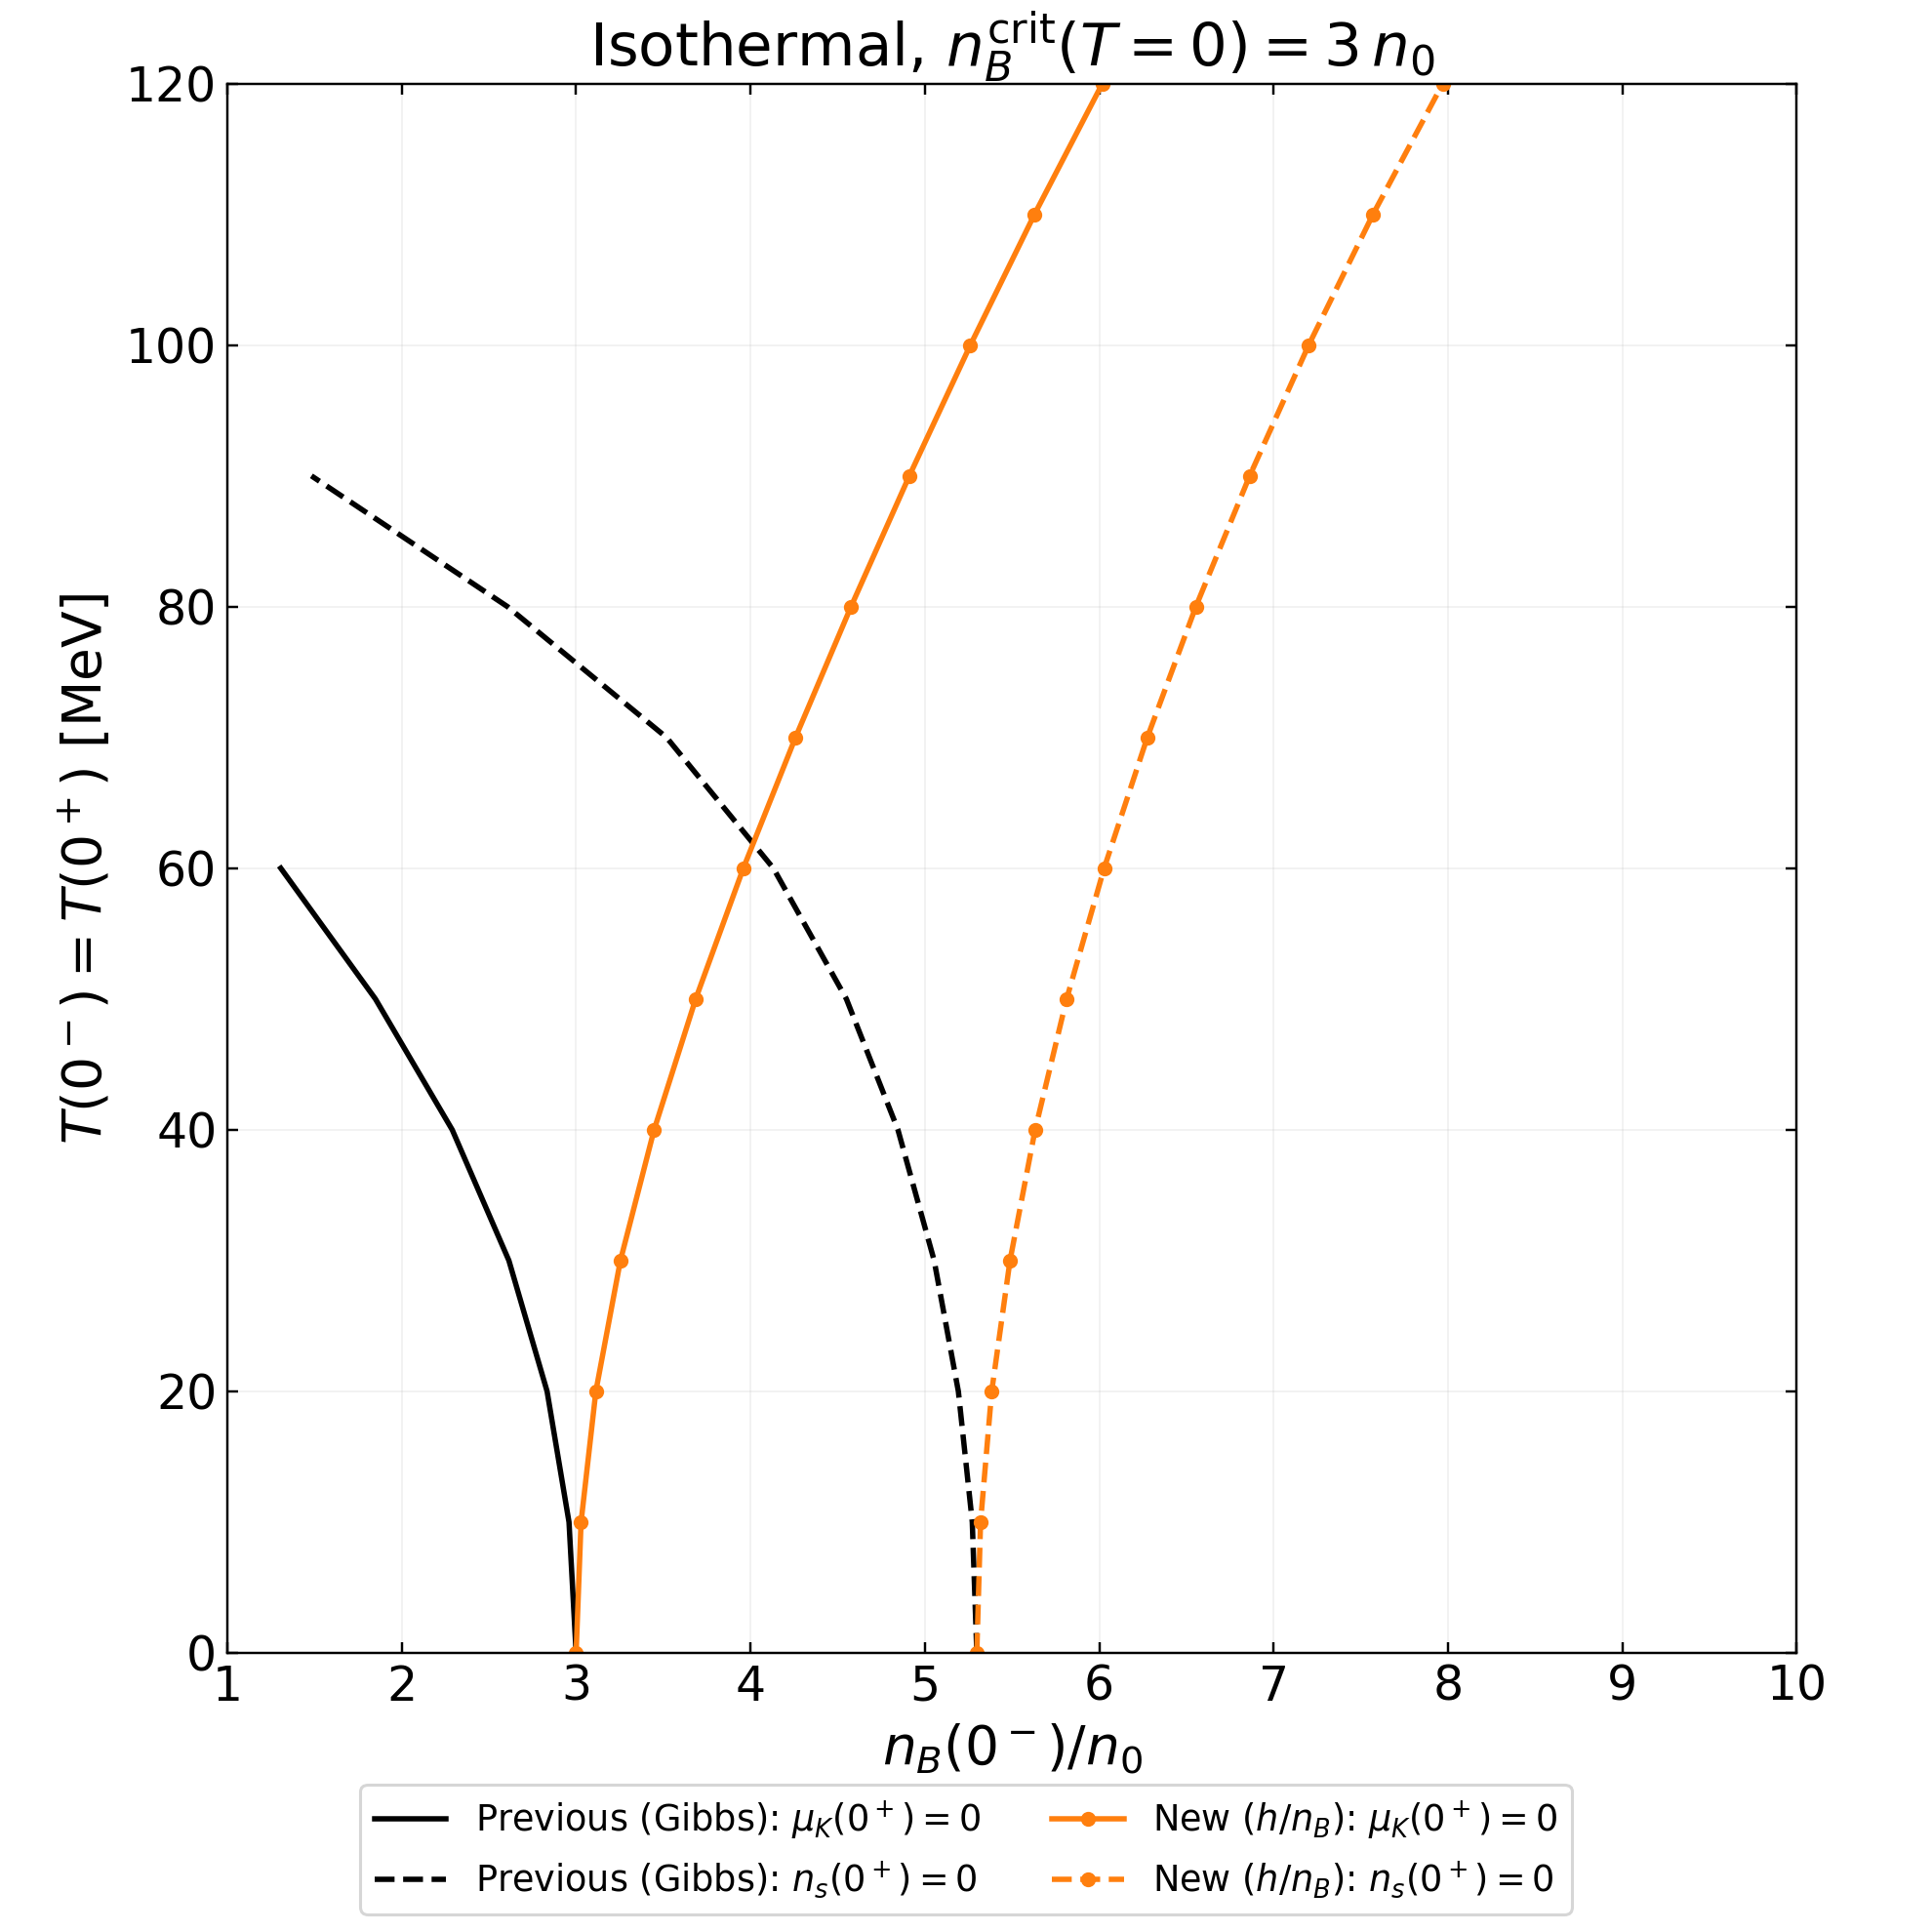

In [ ]:
# Tunable plotting parameters
FIGURE_SIZE = (9.0, 9.0)
FIGURE_DPI = 140
EXPORT_DPI = 220
CONSTRAINED_LAYOUT = True
BOX_ASPECT = 1.0
X_LIMITS = (1.0, 10.0)
Y_LIMITS_MEV = (0.0, 120.0)
X_LABEL = r"$n_B(0^-)/n_0$"
Y_LABEL = r"$T(0^-)=T(0^+)$ [MeV]"
TITLE = rf"Isothermal, $n_B^{{\rm crit}}(T=0)={ISOTHERMAL_NCRIT_OVER_N0:g}\,n_0$"
AXIS_LABEL_FONT_SIZE = 18
TITLE_FONT_SIZE = 20
TICK_LABEL_FONT_SIZE = 16
LEGEND_FONT_SIZE = 12
LEGEND_LOCATION = "outside lower center"
LEGEND_COLUMNS = 2
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
ENTHALPY_COLOR = "#ff7f0e"
GIBBS_COLOR = "black"
BOUNDARY_LINE_STYLES = {"muK": "-", "ns": "--"}
BOUNDARY_LABELS = {"muK": r"$\mu_K(0^+)=0$", "ns": r"$n_s(0^+)=0$"}
METHOD_LABELS = {"gibbs": "Previous (Gibbs)", "enthalpy": r"New ($h/n_B$)"}
ENTHALPY_MARKER = "o"
MARKER_SIZE = 4
LINE_WIDTH = 1.8
GRID_ALPHA = 0.2
GRID_LINE_WIDTH = 0.5
BACKGROUND_COLOR = "white"
OUTPUT_STEM = f"local_analysis_results/FL26-3/isothermal-boundary-test-ncrit{ISOTHERMAL_NCRIT_OVER_N0:g}"
EXPORT_FORMATS = ("png", "pdf")

fig_iso, ax_iso = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI,
                               constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
for balance, color, marker in (("gibbs", GIBBS_COLOR, None),
                                ("enthalpy", ENTHALPY_COLOR, ENTHALPY_MARKER)):
    for condition in ("muK", "ns"):
        rows = isothermal_results.query("condition == @condition and balance == @balance").sort_values("T_MeV")
        density = rows["nB_0minus_over_n0"].where(rows["success"], np.nan)
        ax_iso.plot(density, rows["T_MeV"], color=color, linestyle=BOUNDARY_LINE_STYLES[condition],
                    marker=marker, markersize=MARKER_SIZE, linewidth=LINE_WIDTH,
                    label=f"{METHOD_LABELS[balance]}: {BOUNDARY_LABELS[condition]}")
ax_iso.set(xlim=X_LIMITS, ylim=Y_LIMITS_MEV)
ax_iso.set_facecolor(BACKGROUND_COLOR)
ax_iso.set_box_aspect(BOX_ASPECT)
ax_iso.set_title(TITLE, fontsize=TITLE_FONT_SIZE)
ax_iso.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
ax_iso.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
ax_iso.tick_params(labelsize=TICK_LABEL_FONT_SIZE, direction=TICK_DIRECTION,
                   top=TICKS_TOP, right=TICKS_RIGHT)
ax_iso.grid(alpha=GRID_ALPHA, linewidth=GRID_LINE_WIDTH)
fig_iso.legend(*ax_iso.get_legend_handles_labels(), fontsize=LEGEND_FONT_SIZE,
               loc=LEGEND_LOCATION, ncols=LEGEND_COLUMNS)
for extension in EXPORT_FORMATS:
    output = Path(f"{OUTPUT_STEM}.{extension}")
    output.parent.mkdir(parents=True, exist_ok=True)
    fig_iso.savefig(output, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
plt.show()
